In [1]:
print("heyy")

heyy


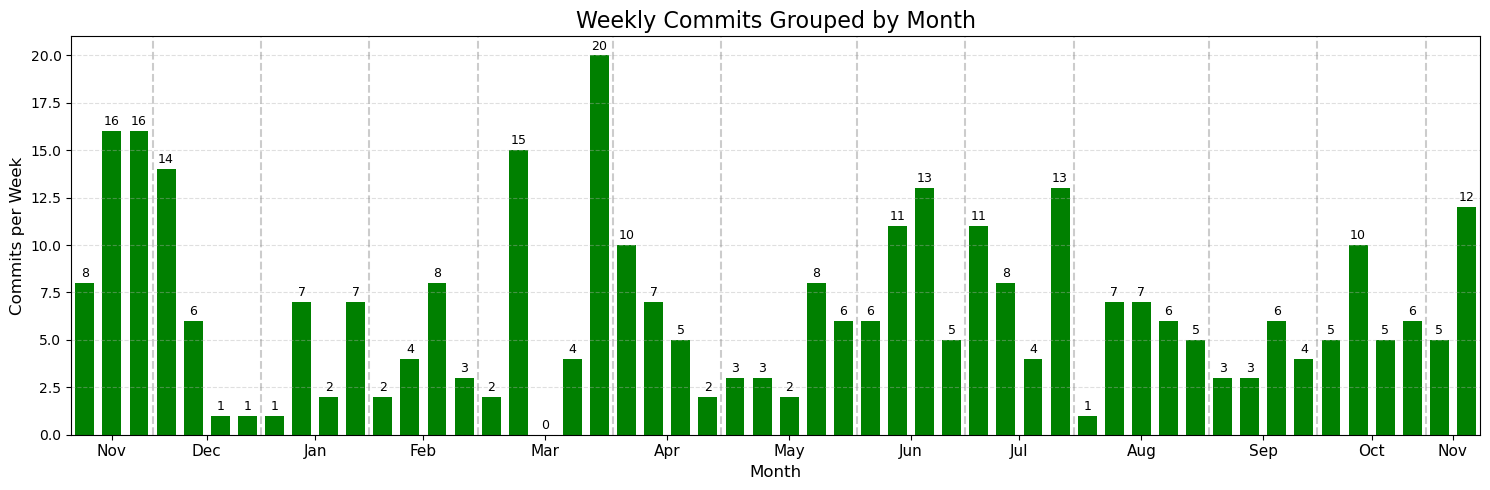

In [16]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Read data
df = pd.read_csv("Commits.csv")
df["DateTime"] = pd.to_datetime(df["DateTime"])

# Sort data chronologically
df = df.sort_values("DateTime").reset_index(drop=True)

# Create positions for bars
x = np.arange(len(df))

# Create chart
fig, ax = plt.subplots(figsize=(15, 5))

ax.bar(
    x,
    df["Commits"],
    color="green",
    width=0.7
)

# Display values above bars
for i, value in enumerate(df["Commits"]):
    ax.text(
        i, value + 0.3, str(value),
        ha="center",
        fontsize=9
    )

# Group using actual year-month periods
df["Month"] = df["DateTime"].dt.to_period("M")

month_groups = df.groupby("Month", sort=True)

month_positions = []
month_labels = []

for month, group in month_groups:
    first = group.index[0]
    last = group.index[-1]

    month_positions.append((first + last) / 2)
    month_labels.append(month.strftime("%b"))

# Set month labels
ax.set_xticks(month_positions)
ax.set_xticklabels(month_labels, fontsize=11)

# Add vertical separators between months
for i in range(1, len(df)):
    if df.loc[i, "Month"] != df.loc[i-1, "Month"]:
        ax.axvline(
            i - 0.5,
            color="gray",
            linestyle="--",
            alpha=0.4
        )

# Set chart boundaries
ax.set_xlim(-0.5, len(df) - 0.5)

# Labels and title
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Commits per Week", fontsize=12)
ax.set_title("Weekly Commits Grouped by Month", fontsize=16)

ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Save chart
plt.savefig(
    "fig2.png",
    dpi=300,
    bbox_inches="tight"
)

# Display chart
plt.show()
